In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [20]:
dataset_path = r"C:\GeoAI\data\fertilizer_recommendation.csv"

In [21]:
df = pd.read_csv(dataset_path)

In [22]:
df.shape[0]

10000

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Soil_Type                    10000 non-null  object 
 1   Soil_pH                      10000 non-null  float64
 2   Soil_Moisture                10000 non-null  float64
 3   Organic_Carbon               10000 non-null  float64
 4   Electrical_Conductivity      10000 non-null  float64
 5   Nitrogen_Level               10000 non-null  int64  
 6   Phosphorus_Level             10000 non-null  int64  
 7   Potassium_Level              10000 non-null  int64  
 8   Temperature                  10000 non-null  float64
 9   Humidity                     10000 non-null  float64
 10  Rainfall                     10000 non-null  float64
 11  Crop_Type                    10000 non-null  object 
 12  Crop_Growth_Stage            10000 non-null  object 
 13  Season           

In [24]:
df.isnull().sum()

Soil_Type                      0
Soil_pH                        0
Soil_Moisture                  0
Organic_Carbon                 0
Electrical_Conductivity        0
Nitrogen_Level                 0
Phosphorus_Level               0
Potassium_Level                0
Temperature                    0
Humidity                       0
Rainfall                       0
Crop_Type                      0
Crop_Growth_Stage              0
Season                         0
Irrigation_Type                0
Previous_Crop                  0
Region                         0
Fertilizer_Used_Last_Season    0
Yield_Last_Season              0
Recommended_Fertilizer         0
dtype: int64

In [25]:
df.describe()

,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Nitrogen_Level,Phosphorus_Level,Potassium_Level,Temperature,Humidity,Rainfall,Fertilizer_Used_Last_Season,Yield_Last_Season
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,6.485728,35.411531,0.844731,1.543156,88.995000,48.965100,64.147000,25.058906,60.093727,1588.085798,176.165508,4.531666
std,1.152964,14.413002,0.372406,0.839514,40.336674,23.195588,31.867211,8.601550,17.386120,810.992404,72.235790,2.013522
min,4.500000,10.000000,0.200000,0.100000,20.000000,10.000000,10.000000,10.000000,30.010000,200.080000,50.010000,1.000000
25%,5.490000,23.030000,0.520000,0.820000,54.000000,29.000000,37.000000,17.580000,44.925000,874.780000,113.175000,2.780000
50%,6.460000,35.645000,0.850000,1.530000,89.000000,49.000000,64.000000,25.085000,60.345000,1594.295000,176.835000,4.550000
75%,7.490000,47.662500,1.160000,2.270000,124.000000,69.000000,92.000000,32.502500,75.420000,2283.782500,239.232500,6.260000
max,8.500000,60.000000,1.500000,3.000000,159.000000,89.000000,119.000000,40.000000,89.990000,2999.980000,300.000000,8.000000


In [26]:
target_col = df.columns[-1]
df[target_col].value_counts()

Recommended_Fertilizer
Urea             3101
DAP              2920
MOP              1408
Compost           996
Zinc Sulphate     752
NPK               641
SSP               182
Name: count, dtype: int64

# Random Undersampling

In [28]:
min_samples = df[target_col].value_counts().min()
print(f"Jumlah sampel minimum per kelas yang akan disamakan: {min_samples}")

Jumlah sampel minimum per kelas yang akan disamakan: 182


In [29]:
balanced_df = df.groupby(target_col, group_keys=False).apply(lambda x: x.sample(n=min_samples, random_state=42))

C:\Users\tuf\AppData\Local\Temp\ipykernel_25288\1155621002.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  balanced_df = df.groupby(target_col, group_keys=False).apply(lambda x: x.sample(n=min_samples, random_state=42))


In [30]:
print(balanced_df[target_col].value_counts())
print(f"\nTotal baris dataset setelah seimbang: {balanced_df.shape[0]}")

Recommended_Fertilizer
Compost          182
DAP              182
MOP              182
NPK              182
SSP              182
Urea             182
Zinc Sulphate    182
Name: count, dtype: int64

Total baris dataset setelah seimbang: 1274


In [31]:
output_dir = r"C:\GeoAI\data"
output_file = os.path.join(output_dir, "fertilizer_recommendation_balanced.csv")
balanced_df.to_csv(output_file, index=False)

# EDA

In [33]:
balanced_file_path = r"C:\GeoAI\data\fertilizer_recommendation_balanced.csv"

In [34]:
df_balanced = pd.read_csv(balanced_file_path)

In [35]:
display(df_balanced.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1274 entries, 0 to 1273
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Soil_Type                    1274 non-null   object 
 1   Soil_pH                      1274 non-null   float64
 2   Soil_Moisture                1274 non-null   float64
 3   Organic_Carbon               1274 non-null   float64
 4   Electrical_Conductivity      1274 non-null   float64
 5   Nitrogen_Level               1274 non-null   int64  
 6   Phosphorus_Level             1274 non-null   int64  
 7   Potassium_Level              1274 non-null   int64  
 8   Temperature                  1274 non-null   float64
 9   Humidity                     1274 non-null   float64
 10  Rainfall                     1274 non-null   float64
 11  Crop_Type                    1274 non-null   object 
 12  Crop_Growth_Stage            1274 non-null   object 
 13  Season            

None

In [36]:
display(df_balanced.describe())

,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Nitrogen_Level,Phosphorus_Level,Potassium_Level,Temperature,Humidity,Rainfall,Fertilizer_Used_Last_Season,Yield_Last_Season
count,1274.000000,1274.000000,1274.000000,1274.000000,1274.000000,1274.000000,1274.000000,1274.000000,1274.000000,1274.000000,1274.000000,1274.000000
mean,6.537802,35.579082,0.845369,1.555188,100.729199,56.688383,68.740188,24.747747,60.271468,1555.541962,176.317677,4.575165
std,1.126845,14.773999,0.367040,0.836191,35.735912,20.308139,30.081912,8.671111,17.310602,815.945953,70.961808,1.984707
min,4.500000,10.030000,0.200000,0.100000,20.000000,10.000000,10.000000,10.000000,30.030000,204.190000,50.030000,1.030000
25%,5.630000,22.210000,0.540000,0.840000,73.000000,44.000000,45.000000,16.865000,45.120000,831.950000,116.575000,2.872500
50%,6.520000,36.110000,0.850000,1.550000,104.000000,58.000000,70.000000,24.565000,60.660000,1536.145000,173.445000,4.560000
75%,7.507500,48.130000,1.157500,2.280000,130.000000,73.000000,94.000000,32.240000,75.560000,2262.082500,239.222500,6.240000
max,8.490000,60.000000,1.500000,3.000000,159.000000,89.000000,119.000000,39.950000,89.990000,2999.430000,299.760000,7.990000


In [38]:
# Tentukan kolom target
target_col = df_balanced.columns[-1]

# Mengambil semua kolom numerik secara otomatis dari dataframe balanced
all_numeric_features = df_balanced.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Menghitung rata-rata (mean) untuk semua fitur numerik berdasarkan jenis pupuk
fertilizer_profile_all = df_balanced.groupby(target_col)[all_numeric_features].mean()

print("--- RATA-RATA LENGKAP SEMUA FITUR NUMERIK BERDASARKAN JENIS PUPUK ---")
display(fertilizer_profile_all)

--- RATA-RATA LENGKAP SEMUA FITUR NUMERIK BERDASARKAN JENIS PUPUK ---


,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Nitrogen_Level,Phosphorus_Level,Potassium_Level,Temperature,Humidity,Rainfall,Fertilizer_Used_Last_Season,Yield_Last_Season
Recommended_Fertilizer,,,,,,,,,,,,
Compost,5.326868,36.545000,0.845495,1.579121,110.038462,64.879121,76.807692,24.723516,59.058571,1594.498297,172.580824,4.419725
DAP,6.468736,34.371593,0.873626,1.637912,109.813187,27.395604,68.280220,24.878242,60.336648,1529.452582,177.605330,4.490824
MOP,6.527363,35.867473,0.880440,1.611923,110.994505,63.505495,33.390110,24.081758,59.305824,1580.751648,175.703846,4.712308
NPK,6.561099,35.487637,0.827143,1.491154,107.928571,63.142857,78.967033,24.801813,63.306703,1477.033022,178.812418,4.615989
SSP,6.627912,35.391813,0.776538,1.489835,108.576923,63.642857,79.686813,25.886319,58.901703,1584.751593,178.979341,4.624286
Urea,6.552582,36.083516,0.886648,1.543571,45.049451,48.642857,63.780220,24.198077,61.302143,1460.177473,172.622418,4.325714
Zinc Sulphate,7.700055,35.306538,0.827692,1.532802,112.703297,65.609890,80.269231,24.664505,59.688681,1662.129121,177.919560,4.837308


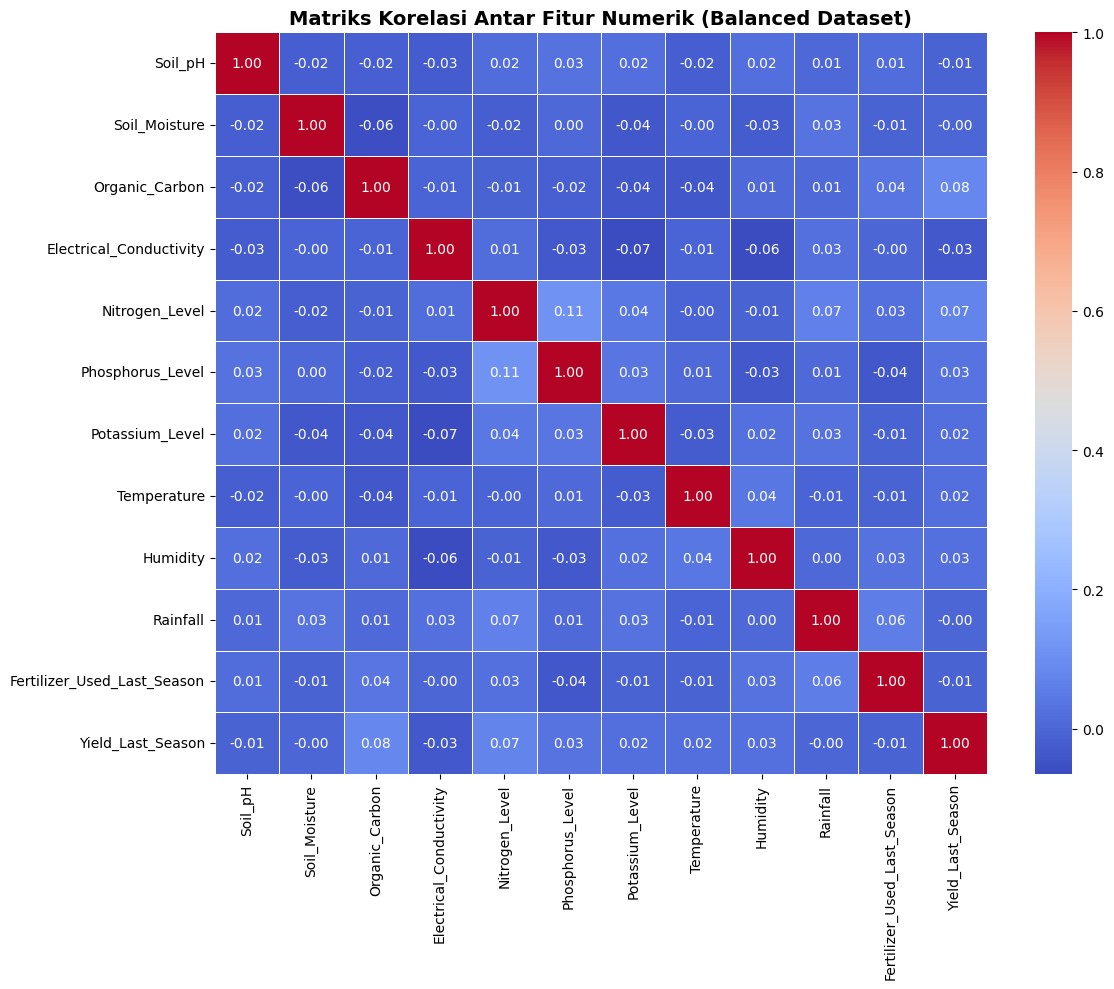

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pilih hanya kolom numerik
numeric_df = df_balanced.select_dtypes(include=['int64', 'float64'])

# Hitung matriks korelasi
corr_matrix = numeric_df.corr()

# Visualisasikan dengan Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)
plt.title("Matriks Korelasi Antar Fitur Numerik (Balanced Dataset)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

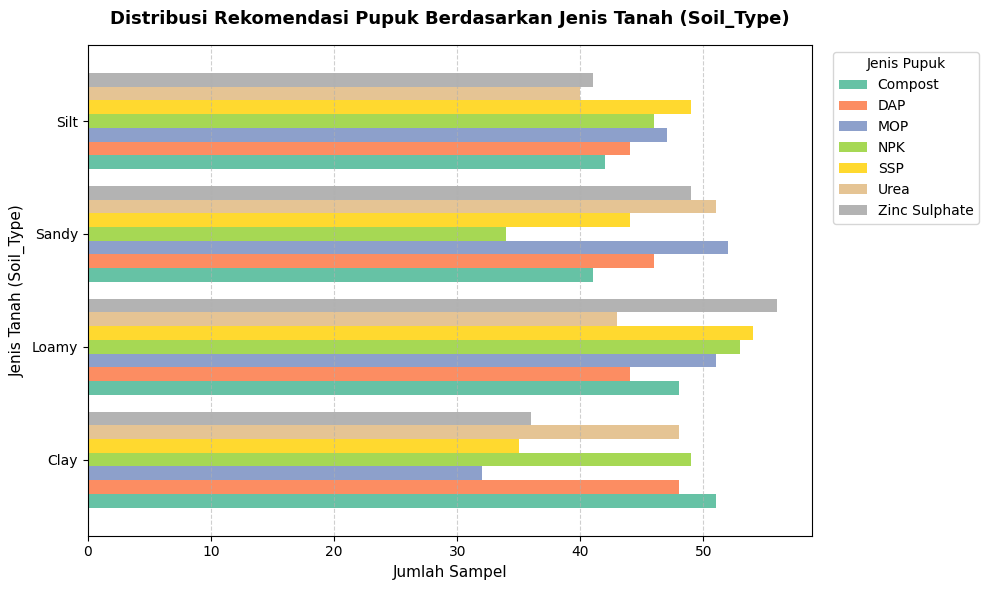

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Membuat tabel silang (crosstab) antara jenis tanah dan rekomendasi pupuk
ct_soil = pd.crosstab(df_balanced['Soil_Type'], df_balanced['Recommended_Fertilizer'])

# 2. Membuat visualisasi Horizontal Bar Chart agar nama dan perbandingannya jelas
fig, ax = plt.subplots(figsize=(10, 6))
ct_soil.plot(kind='barh', ax=ax, colormap='Set2', width=0.85)

# 3. Pengaturan tata letak dan label agar rapi
plt.title("Distribusi Rekomendasi Pupuk Berdasarkan Jenis Tanah (Soil_Type)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Jumlah Sampel", fontsize=11)
plt.ylabel("Jenis Tanah (Soil_Type)", fontsize=11)
plt.legend(title='Jenis Pupuk', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

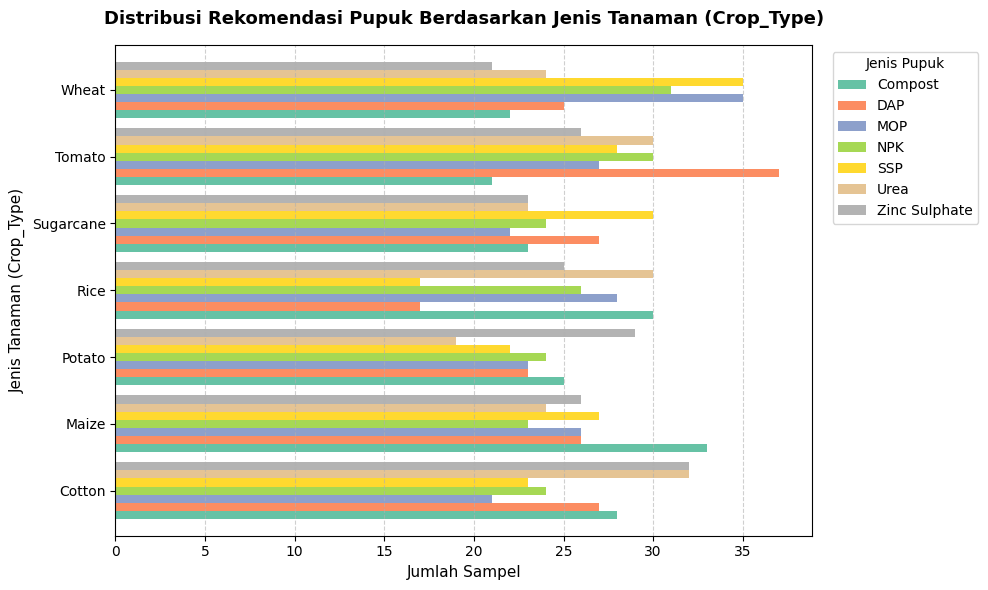

In [43]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Membuat tabel silang (crosstab) antara jenis tanaman dan rekomendasi pupuk
ct_crop = pd.crosstab(df_balanced['Crop_Type'], df_balanced['Recommended_Fertilizer'])

# 2. Membuat visualisasi Horizontal Bar Chart khusus Crop_Type
fig, ax = plt.subplots(figsize=(10, 6))
ct_crop.plot(kind='barh', ax=ax, colormap='Set2', width=0.85)

# 3. Pengaturan tata letak, judul, dan label agar rapi
plt.title("Distribusi Rekomendasi Pupuk Berdasarkan Jenis Tanaman (Crop_Type)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Jumlah Sampel", fontsize=11)
plt.ylabel("Jenis Tanaman (Crop_Type)", fontsize=11)
plt.legend(title='Jenis Pupuk', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

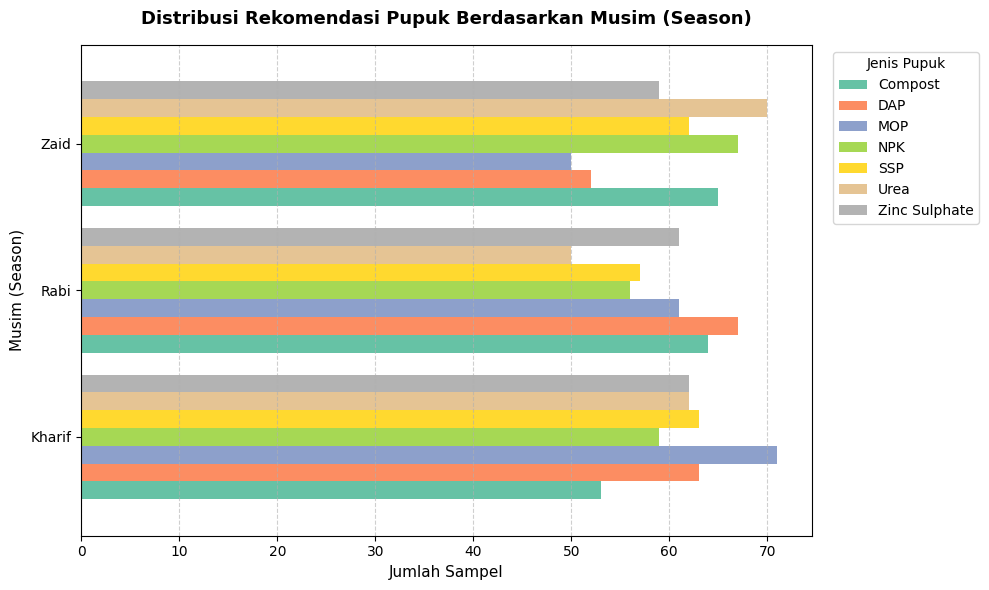

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Membuat tabel silang (crosstab) antara musim dan rekomendasi pupuk
ct_season = pd.crosstab(df_balanced['Season'], df_balanced['Recommended_Fertilizer'])

# 2. Membuat visualisasi Horizontal Bar Chart khusus Season
fig, ax = plt.subplots(figsize=(10, 6))
ct_season.plot(kind='barh', ax=ax, colormap='Set2', width=0.85)

# 3. Pengaturan tata letak, judul, dan label agar rapi
plt.title("Distribusi Rekomendasi Pupuk Berdasarkan Musim (Season)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Jumlah Sampel", fontsize=11)
plt.ylabel("Musim (Season)", fontsize=11)
plt.legend(title='Jenis Pupuk', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

C:\Users\tuf\AppData\Local\Temp\ipykernel_25288\322590294.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_balanced, x=target_col, y=feature, palette='Set3')
C:\Users\tuf\AppData\Local\Temp\ipykernel_25288\322590294.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_balanced, x=target_col, y=feature, palette='Set3')
C:\Users\tuf\AppData\Local\Temp\ipykernel_25288\322590294.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_balanced, x=target_col, y=feature, palette='Set3')
C:\Users\tuf\AppData\Local\Temp\ipykerne

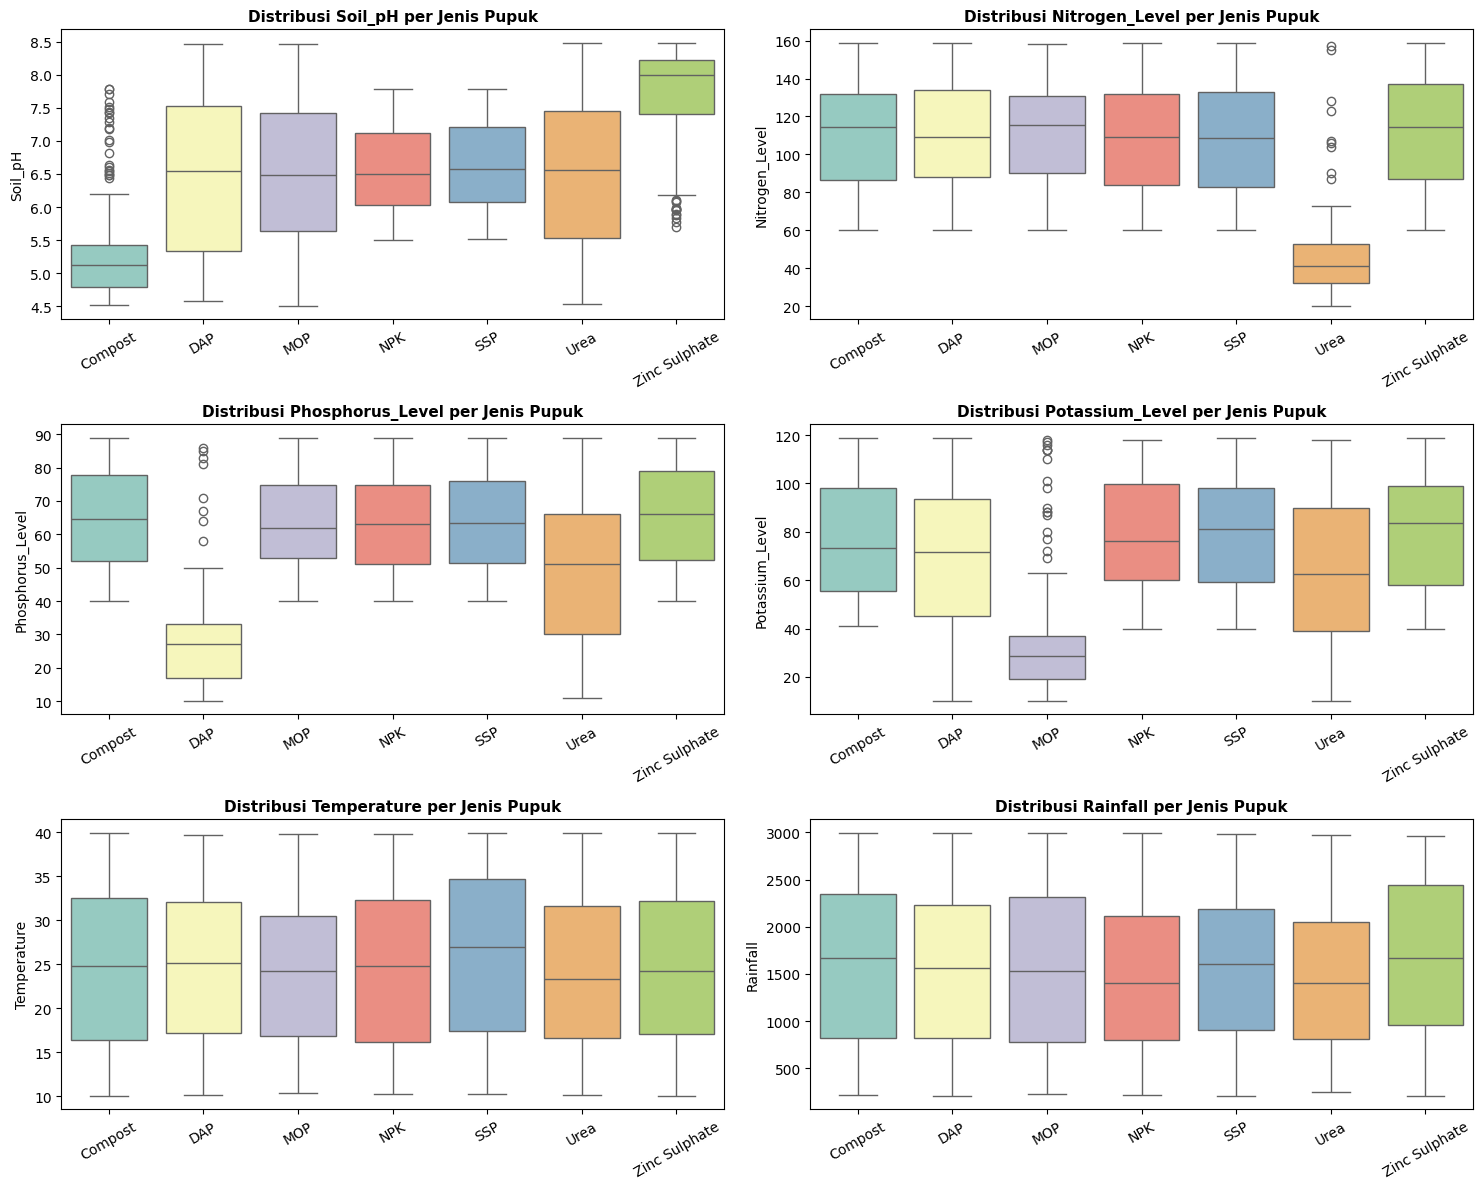

In [41]:
# Pilih beberapa fitur penting untuk divisualisasikan dengan boxplot terhadap target pupuk
import math

features_to_plot = ['Soil_pH', 'Nitrogen_Level', 'Phosphorus_Level', 'Potassium_Level', 'Temperature', 'Rainfall']

plt.figure(figsize=(15, 12))
for i, feature in enumerate(features_to_plot, 1):
    plt.subplot(3, 2, i)
    sns.boxplot(data=df_balanced, x=target_col, y=feature, palette='Set3')
    plt.title(f"Distribusi {feature} per Jenis Pupuk", fontsize=11, fontweight='bold')
    plt.xticks(rotation=30)
    plt.xlabel("")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

# Preprocessing & Train-Test Split

In [45]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load dataset yang sudah seimbang
df_balanced = pd.read_csv(r"C:\GeoAI\data\fertilizer_recommendation_balanced.csv")

# 2. Pisahkan antara Fitur (X) dan Target (y)
target_col = df_balanced.columns[-1]
X = df_balanced.drop(columns=[target_col])
y = df_balanced[target_col]

# 3. Ubah fitur kategorikal menjadi numerik menggunakan One-Hot Encoding (pd.get_dummies)
X_encoded = pd.get_dummies(X, drop_first=True)

print(f"Jumlah fitur setelah encoding: {X_encoded.shape[1]}")

# 4. Bagi data menjadi Data Latih (80%) dan Data Uji (20%) 
# Menggunakan stratify=y agar proporsi kelas di train dan test seimbang
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Total baris Data Latih (X_train): {X_train.shape[0]}")
print(f"Total baris Data Uji (X_test): {X_test.shape[0]}")

Jumlah fitur setelah encoding: 39
Total baris Data Latih (X_train): 1019
Total baris Data Uji (X_test): 255
